Q7: Data Loading, Storage and File Formats

Analyzing sales data from CSV, JSON and Excel files.

These files contain the same orders in different formats. Count each Order_ID once after combining them.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

salesCSV = pd.read_csv("sales_data.csv")
salesJSON = pd.read_json("sales_data.json")
salesExcel = pd.read_excel("sales_data.xlsx")

for name, data in [("CSV", salesCSV), ("JSON", salesJSON), ("Excel", salesExcel)]:
    print(name, "Data:")
    print(data.head())
    data.info()

CSV Data:
   Order_ID        Date   Product     Category  Quantity  Price Customer Region
0      1001  2026-01-05    Laptop  Electronics       2.0  60000     Amit   West
1      1002  2026-01-08     Mouse  Accessories       5.0    800    Rahul  North
2      1003  2026-01-12  Keyboard  Accessories       3.0   1500    Priya  South
3      1004  2026-01-18   Monitor  Electronics       2.0  12000    Sneha   West
4      1005  2026-02-03    Laptop  Electronics       1.0  60000     Amit   East
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  15 non-null     int64  
 1   Date      15 non-null     object 
 2   Product   15 non-null     object 
 3   Category  15 non-null     object 
 4   Quantity  14 non-null     float64
 5   Price     15 non-null     int64  
 6   Customer  14 non-null     object 
 7   Region    15 non-null     object 
dtypes: float64(1)

In [2]:
# Check missing values
print("Missing Values in CSV:")
print(salesCSV.isnull().sum())

print("\nMissing Values in JSON:")
print(salesJSON.isnull().sum())

print("\nMissing Values in Excel:")
print(salesExcel.isnull().sum())

Missing Values in CSV:
Order_ID    0
Date        0
Product     0
Category    0
Quantity    1
Price       0
Customer    1
Region      0
dtype: int64

Missing Values in JSON:
Order_ID    0
Date        0
Product     0
Category    0
Quantity    1
Price       0
Customer    1
Region      0
dtype: int64

Missing Values in Excel:
Order_ID    0
Date        0
Product     0
Category    0
Quantity    1
Price       0
Customer    1
Region      0
dtype: int64


In [3]:
# Remove missing values and duplicates, then convert dates
def cleaning_data(data):
    data.dropna(inplace=True)
    data["Date"] = pd.to_datetime(data["Date"])
    data.drop_duplicates(inplace=True)
    return data

for data in [salesCSV, salesJSON, salesExcel]:
    cleaning_data(data)

In [4]:
# Combine file formats and count each order once
salesCSV["source"] = "CSV"
salesJSON["source"] = "JSON"
salesExcel["source"] = "Excel"

df = pd.concat([salesCSV, salesExcel, salesJSON], ignore_index=True)
print("Combined Shape:", df.shape)
df = df.drop_duplicates(subset="Order_ID").reset_index(drop=True)
print("Unique Orders:", len(df))
print(df.head())

Combined Shape: (36, 9)
Unique Orders: 12
   Order_ID       Date   Product     Category  ...  Price  Customer Region source
0      1001 2026-01-05    Laptop  Electronics  ...  60000      Amit   West    CSV
1      1002 2026-01-08     Mouse  Accessories  ...    800     Rahul  North    CSV
2      1003 2026-01-12  Keyboard  Accessories  ...   1500     Priya  South    CSV
3      1004 2026-01-18   Monitor  Electronics  ...  12000     Sneha   West    CSV
4      1005 2026-02-03    Laptop  Electronics  ...  60000      Amit   East    CSV

[5 rows x 9 columns]


In [5]:
# Calculate sales and extract date details
df["total_sales"] = df["Quantity"] * df["Price"]
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_name"] = df["Date"].dt.month_name()

In [6]:
print(df.head())

   Order_ID       Date   Product  ...  Year  Month  Month_name
0      1001 2026-01-05    Laptop  ...  2026      1     January
1      1002 2026-01-08     Mouse  ...  2026      1     January
2      1003 2026-01-12  Keyboard  ...  2026      1     January
3      1004 2026-01-18   Monitor  ...  2026      1     January
4      1005 2026-02-03    Laptop  ...  2026      2    February

[5 rows x 13 columns]


In [7]:
# Sales analysis
total_sales = df["total_sales"].sum()
average_order_value = df["total_sales"].mean()

print("Total Sales:", round(total_sales, 2))
print("Average Order Value:", round(average_order_value, 2))

Total Sales: 382200.0
Average Order Value: 31850.0


Product
Headphones      7500.0
Keyboard        7500.0
Laptop        300000.0
Monitor        60000.0
Mouse           7200.0
Name: total_sales, dtype: float64


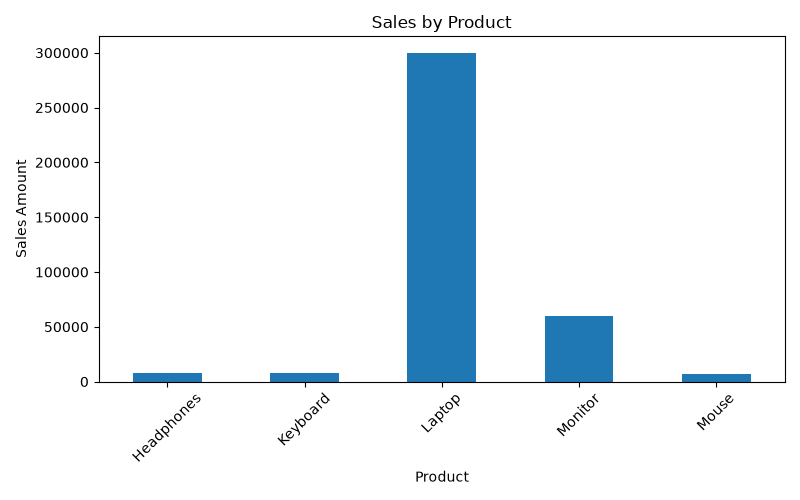

In [8]:
# Compare product sales
product_sales = df.groupby("Product")["total_sales"].sum()
print(product_sales)
product_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

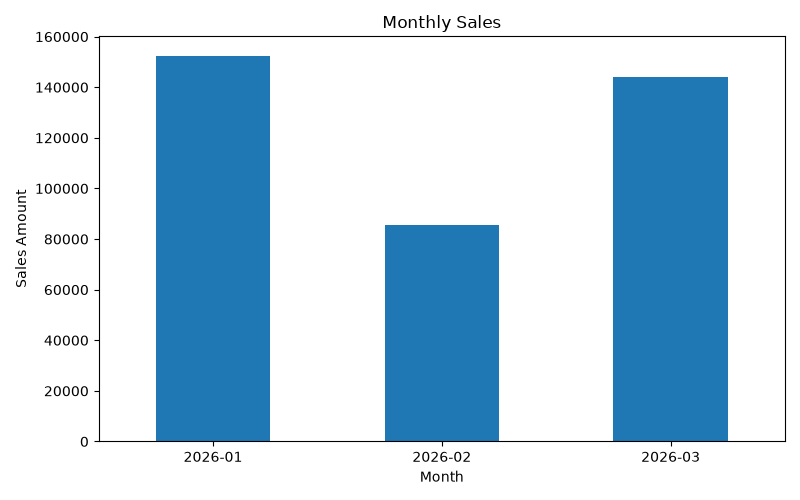

In [9]:
# Monthly sales trend
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["total_sales"].sum()
monthly_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()